# 04 - Compare the three models, choose the best, tune decoding

1. table of the three models (the winner is chosen on the **validation** set, never on test)
2. greedy vs **prefix beam search** vs beam search + a **character language model** (trained on training text only); beam width and LM weights are tuned on validation pages
3. final test score, and an error analysis (which characters are confused, does CER depend on the number of lines?)

In [1]:
import sys, json
sys.path.insert(0, ".")            # htr_data.py and htr_torch.py sit next to this notebook
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import htr_data as D
import htr_torch as T

cfg  = T.load_cfg()                # written by notebook 00
data = T.load_data(cfg)
(cfg["out"] / "figures").mkdir(exist_ok=True)
print("device :", T.get_device())
print("pages  :", {k: len(data[k]) for k in ("train", "val", "test")}, "| classes incl. blank:", T.n_classes(data))

device : cpu
pages  : {'train': 361, 'val': 87, 'test': 90} | classes incl. blank: 156


## 1. Model comparison

not found: cnn_d8 (cnn_d8 and bilstm are optional; cnn, tcn and transformer need their notebook run first)
not found: bilstm (cnn_d8 and bilstm are optional; cnn, tcn and transformer need their notebook run first)
        tag  down  params  best_epoch  train_minutes  val_CER  val_WER  test_CER  test_WER
        cnn     4 1428860          58          427.3   0.3675   0.7427    0.2313    0.6295
        tcn     8 2746748          50          194.6   0.3595   0.7133    0.2304    0.6127
transformer     8 3142780          44          257.5   0.3953   0.7976    0.2686    0.6939

best model on validation: tcn


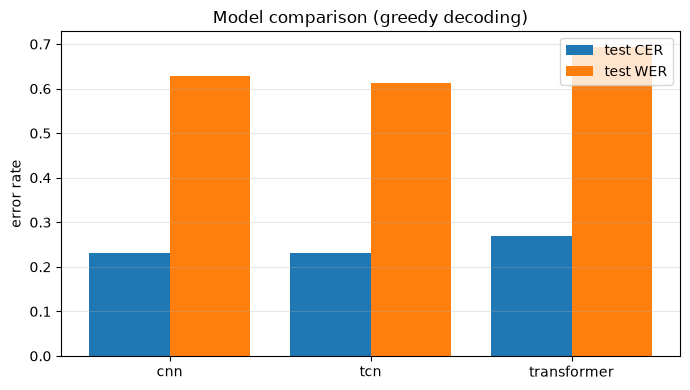

In [2]:
rows = []
for m in ["cnn", "cnn_d8", "tcn", "transformer", "bilstm"]:
    p = cfg["out"] / "results" / f"{m}_metrics.json"
    if p.exists():
        rows.append(json.load(open(p)))
    else:
        print("not found:", m, "(cnn_d8 and bilstm are optional; cnn, tcn and transformer need their notebook run first)")
comp = pd.DataFrame(rows)
if "down" not in comp: comp["down"] = np.nan
comp["down"] = comp["down"].fillna(4).astype(int)            # results of the first CNN run used downsampling 4
comp = comp[["tag", "down", "params", "best_epoch", "train_minutes", "val_CER", "val_WER", "test_CER", "test_WER"]]
print(comp.round(4).to_string(index=False))
comp.to_csv(cfg["out"] / "results" / "model_comparison.csv", index=False)

best_tag = comp.sort_values("val_CER").iloc[0]["tag"]          # chosen on VALIDATION
print("\nbest model on validation:", best_tag)

x = np.arange(len(comp))
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - 0.2, comp.test_CER, 0.4, label="test CER"); ax.bar(x + 0.2, comp.test_WER, 0.4, label="test WER")
ax.set_xticks(x); ax.set_xticklabels(comp.tag); ax.set_ylabel("error rate"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Model comparison (greedy decoding)")
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / "model_comparison.png", dpi=150); plt.show()

## 2. Decoding with the best model

We keep the network output (log-probabilities) and only change how it is turned into text.

In [3]:
model, res = T.evaluate_checkpoint(best_tag, data, cfg, keep_logp=True)
val_lp,  test_lp  = res["val"]["logps"],  res["test"]["logps"]
val_ref, test_ref = list(res["val"]["df"].reference), list(res["test"]["df"].reference)
idx2char = data["idx2char"]
lm = D.CharNgramLM(order=5).fit(list(data["train"].text))      # training text only
print("pages:", len(val_lp), "val /", len(test_lp), "test")

pages: 87 val / 90 test


In [4]:
N = min(45, len(val_lp))          # tune on a subset of validation pages (beam search is slow in pure Python)

def decode_all(lps, beam, alpha=0.0, beta=0.0):
    return [D.prefix_beam_search(lp, idx2char, beam, lm=lm if alpha > 0 else None, alpha=alpha, beta=beta) for lp in lps]

results = []
g = [D.greedy_decode(lp, idx2char) for lp in val_lp[:N]]
results.append(dict(decoder="greedy", beam=0, alpha=0.0, beta=0.0, CER=D.corpus_cer(val_ref[:N], g), WER=D.corpus_wer(val_ref[:N], g)))
for beam in [3, 10, 20]:
    hyp = decode_all(val_lp[:N], beam)
    results.append(dict(decoder="beam", beam=beam, alpha=0.0, beta=0.0, CER=D.corpus_cer(val_ref[:N], hyp), WER=D.corpus_wer(val_ref[:N], hyp)))
for alpha in [0.3, 0.6, 1.0]:
    for beta in [0.0, 0.5, 1.0]:
        hyp = decode_all(val_lp[:N], 10, alpha, beta)
        results.append(dict(decoder="beam+LM", beam=10, alpha=alpha, beta=beta, CER=D.corpus_cer(val_ref[:N], hyp), WER=D.corpus_wer(val_ref[:N], hyp)))
tune = pd.DataFrame(results).sort_values("CER").reset_index(drop=True)
print(tune.round(4).to_string(index=False))
tune.to_csv(cfg["out"] / "results" / "decoder_tuning_val.csv", index=False)
best = tune.iloc[0]
print("\nchosen on validation:", dict(best))

decoder  beam  alpha  beta    CER    WER
beam+LM    10    0.3   1.0 0.3747 0.6156
   beam    10    0.0   0.0 0.3865 0.6636
   beam    20    0.0   0.0 0.3866 0.6656
beam+LM    10    0.3   0.5 0.3889 0.6202
   beam     3    0.0   0.0 0.3898 0.6636
beam+LM    10    0.6   1.0 0.3963 0.6249
 greedy     0    0.0   0.0 0.3969 0.6729
beam+LM    10    0.3   0.0 0.4065 0.6336
beam+LM    10    0.6   0.5 0.4162 0.6393
beam+LM    10    0.6   0.0 0.4384 0.6574
beam+LM    10    1.0   1.0 0.4443 0.6641
beam+LM    10    1.0   0.5 0.4707 0.6889
beam+LM    10    1.0   0.0 0.4966 0.7105

chosen on validation: {'decoder': 'beam+LM', 'beam': np.int64(10), 'alpha': np.float64(0.3), 'beta': np.float64(1.0), 'CER': np.float64(0.3747381023645615), 'WER': np.float64(0.6155830753353974)}


In [5]:
final = dict(tag=best_tag, decoder=str(best.decoder), beam=int(best.beam), alpha=float(best.alpha), beta=float(best.beta))
test_greedy = [D.greedy_decode(lp, idx2char) for lp in test_lp]
test_final  = test_greedy if final["decoder"] == "greedy" else decode_all(test_lp, final["beam"], final["alpha"], final["beta"])

summary = pd.DataFrame([
    dict(decoder="greedy", CER=D.corpus_cer(test_ref, test_greedy), WER=D.corpus_wer(test_ref, test_greedy)),
    dict(decoder=f"final ({final['decoder']}, beam={final['beam']}, alpha={final['alpha']}, beta={final['beta']})",
         CER=D.corpus_cer(test_ref, test_final), WER=D.corpus_wer(test_ref, test_final)),
])
print(summary.round(4).to_string(index=False))

fin = res["test"]["df"][["id", "language", "reference"]].copy()
fin["greedy"], fin["prediction"] = test_greedy, test_final
fin["CER"] = [D.cer(r, p) for r, p in zip(fin.reference, fin.prediction)]
fin["WER"] = [D.wer(r, p) for r, p in zip(fin.reference, fin.prediction)]
fin.to_csv(cfg["out"] / "results" / "test_final_predictions.csv", index=False, encoding="utf-8-sig")
final.update(test_CER=float(summary.CER.iloc[1]), test_WER=float(summary.WER.iloc[1]), greedy_test_CER=float(summary.CER.iloc[0]))
json.dump(final, open(cfg["out"] / "results" / "final_decoder.json", "w"), indent=2)
print("\nsaved final_decoder.json and test_final_predictions.csv")

                                      decoder    CER    WER
                                       greedy 0.2304 0.6127
final (beam+LM, beam=10, alpha=0.3, beta=1.0) 0.1992 0.5005

saved final_decoder.json and test_final_predictions.csv


If beam search or the language model does not help, that is a valid result - report it as it is. A 5-gram character LM trained on ~300 paragraphs is small.

## 3. Error analysis

In [6]:
from collections import Counter
sub, dele, ins = Counter(), Counter(), Counter()
for r, h in zip(fin.reference, fin.prediction):
    for op, a, b in D.align_ops(r, h):
        if op == "sub":   sub[(a, b)] += 1
        elif op == "del": dele[a] += 1
        else:             ins[b] += 1
total_ref = sum(len(r) for r in fin.reference)
print(f"substitutions {sum(sub.values())}  deletions {sum(dele.values())}  insertions {sum(ins.values())}  (reference chars: {total_ref})")
print("\nmost frequent substitutions (reference -> predicted):")
for (a, b), c in sub.most_common(15):
    print(f"   {a!r} -> {b!r}   x{c}")
print("\nmost frequently deleted characters:", dele.most_common(10))
print("most frequently inserted characters:", ins.most_common(10))

substitutions 1827  deletions 2103  insertions 437  (reference chars: 21925)

most frequent substitutions (reference -> predicted):
   'ल' -> 'न'   x31
   'त' -> 'न'   x26
   'म' -> 'य'   x23
   'ब' -> 'व'   x23
   'थ' -> 'य'   x20
   'ग' -> 'ा'   x16
   'व' -> 'त'   x16
   'ल' -> 'त'   x15
   'त' -> 'ा'   x15
   'ब' -> 'त'   x13
   'ह' -> 'द'   x13
   'े' -> 'ो'   x12
   'य' -> 'प'   x12
   'र' -> 'ा'   x11
   'म' -> 'स'   x11

most frequently deleted characters: [('्', 201), (' ', 173), ('ं', 137), ('र', 136), ('ा', 106), ('त', 87), ('े', 76), ('क', 70), ('ह', 59), ('ि', 56)]
most frequently inserted characters: [('्', 57), (' ', 54), ('ा', 43), ('ं', 37), ('र', 26), ('.', 22), ('क', 16), ('।', 15), ('त', 12), ('द', 11)]


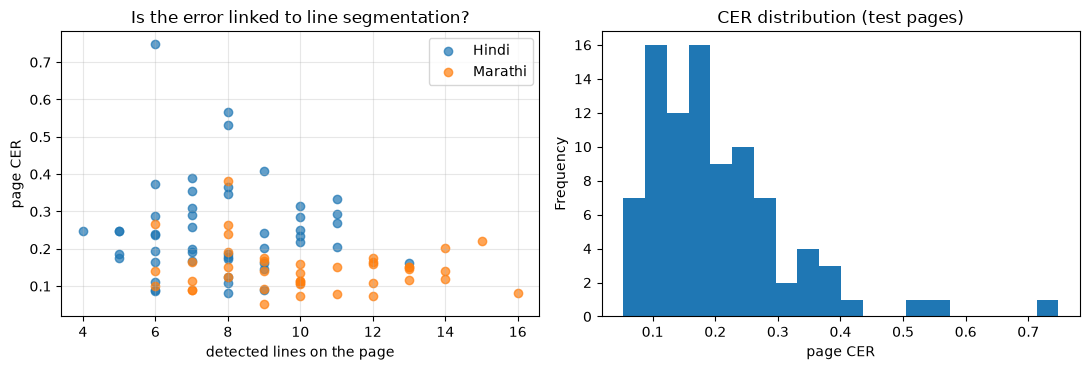

--- hi_138_46373 (Hindi) CER 0.532
reference : इन खतों में उन्होंने अपनी कदरदानी दिखायी। फिर तुम लोग (दोबार की) क्यों नहीं तस्दीक़ करते यह गुरुत्वाकर्षण के कारण को धीमा करना जा रहा है। संदेश हस्ताक्षर की जां
prediction: ये उन्होंने आ्ी प्रतावी लोग्य दिीबार की) त्यों न्ी महास कर्षण के कारण को धीया है। श्र की जाच वही कर सकता प्रार के दौरान हम अपनी स्थान  पके।

--- hi_138_44117 (Hindi) CER 0.565
reference : अजंता का कलामंडप इसका अद्भुत प्रमाण है। पुलिस कब तक और कितने दिनों तक हमारी रक्षा करेगी। मैं किसी आप से बेहतर प्यार करता है नहीं लगता है। उन्होने भी थोडे दिनो म
prediction: या आज हा सरा सादर उुलिस कळ लक पो जचात इुमारी रक्षा केली। मैं किसी आप से बेहतर पार करता है। रा ा ा ा ा ा ा ा ा ें  त्ह संभव नहीं हो।

--- hi_138_42899 (Hindi) CER 0.748
reference : जिसको गुनेहगारों के सिवा कोई नहीं खाएगा वह हमारे द्वारा संभाली गयी नौकाओं से बिल्कुल अलग थी। हम क्यों यकीन रख सकते हैं कि यहोवा हमें बचाएगा? और हम १९८३ का विश्व
prediction: हा ा ा ा ा ा ा ा ा ा ा ा ा ा ा या रा ा?.   ु ुत ु त त ा ा ा ो ा मा

In [7]:
man = data["manifest"][["id", "n_lines", "strip_w", "dropped_heading"]]
m = fin.merge(man, on="id")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for lang, g in m.groupby("language"):
    ax[0].scatter(g.n_lines, g.CER, label=lang, alpha=.7)
ax[0].set_xlabel("detected lines on the page"); ax[0].set_ylabel("page CER"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("Is the error linked to line segmentation?")
fin.CER.plot.hist(ax=ax[1], bins=20); ax[1].set_xlabel("page CER"); ax[1].set_title("CER distribution (test pages)")
plt.tight_layout(); plt.savefig(cfg["out"] / "figures" / "error_analysis.png", dpi=150); plt.show()

worst = fin.sort_values("CER").tail(3)
for _, r in worst.iterrows():
    print(f"--- {r.id} ({r.language}) CER {r.CER:.3f}\nreference : {r.reference[:160]}\nprediction: {r.prediction[:160]}\n")
print("next: notebook 05")